# Resolución del video y precisión del centro de la partícula

Los análisis de la pinza hablan de movimientos de 20 a 50 nm, y un píxel de la cámara mide 95 nm. Este notebook responde tres preguntas:

1. **¿Qué resolución tiene el video?** Tamaño del píxel, nitidez de la óptica y ruido de la cámara.
2. **¿Con qué precisión se mide el centro de una partícula?** Y cómo puede ser menor que un píxel.
3. **¿Qué tan redondas se ven las partículas?**

Usa partículas **pegadas al vidrio** de `BARRIDO 1`: como no se mueven, todo lo que «se mueve» su centro medido es error de medición. Lee los videos originales de `C:\datos_pinzas\GRABACIONES` (hacen falta para ejecutarlo). Funciones en `codigo/resolucion.py`.

Salidas: `resultados/resolucion_*.csv` y `figuras/`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "codigo")))      # las funciones están en pinzas ópticas/codigo/
from carpetas import figuras, resultados                            # dónde va cada cosa, por objetivo
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import resolucion as rs
import trampa_roi as tr
from pinzas_datos import RAIZ, DATOS, ESCALA_UM

plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE, AZUL = "#2A9D8F", "#E76F51", "#264653", "#4C72B0"
FIGURAS = figuras("comun")
SALIDA = resultados("comun")
os.makedirs(FIGURAS, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
NM = rs.NM_PX                       # nm por px
resumen = []                        # (qué, valor, unidad, cómo se midió)


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".svg"), bbox_inches="tight")


def csv(tabla, nombre):
    tabla.to_csv(os.path.join(SALIDA, nombre), index=False, float_format="%.5g")


def anotar(que, valor, unidad, como):
    resumen.append(dict(magnitud=que, valor=valor, unidad=unidad, como=como))


GRAB = "BARRIDO 1"
pags = tr.paginas(GRAB)
fondo = rs.fondo_mediana(pags)
print("%s: %d cuadros de %d × %d px | 1 px = %.2f nm | campo de %.0f × %.0f µm"
      % (GRAB, len(pags), fondo.shape[1], fondo.shape[0], NM, fondo.shape[1] * ESCALA_UM, fondo.shape[0] * ESCALA_UM))
anotar("tamaño del píxel", NM, "nm", "retícula de 0.01 mm (escala y catálogo)")

BARRIDO 1: 3219 cuadros de 1280 × 1024 px | 1 px = 94.61 nm | campo de 121 × 97 µm


## 1. Resolución del video

### El píxel y la partícula

Un píxel mide 94.6 nm. Una partícula de tamaño nominal se ve con unos 37 px de diámetro: ocupa **más de mil píxeles**. Esa es la clave de todo lo que sigue: el centro no se lee de un píxel, sale de combinar todos.

partícula 340: radio del borde 19.5 px = 1.84 µm → diámetro 39 px, unos 1192 píxeles adentro
13 partículas quietas en BARRIDO 1 (pegadas al vidrio: no se mueven con la platina quieta)


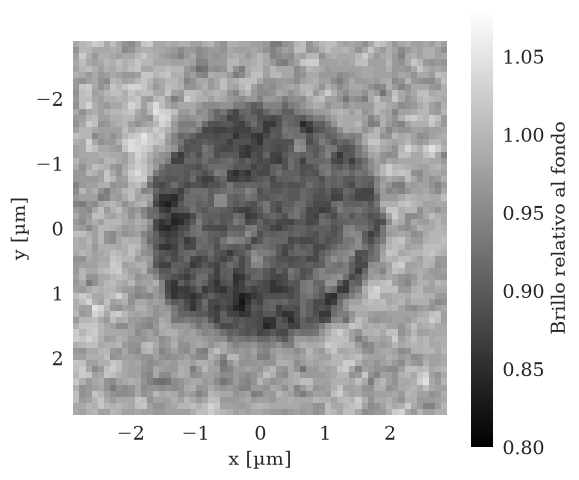

In [2]:
q = rs.quietas(GRAB)
csv(q, "resolucion_quietas.csv")
ejemplo = q[q.particula == 340].iloc[0]                     # una partícula quieta, lejos del borde de la imagen
un_cuadro = rs.recorte(rs.cuadro_verde(pags[int(ejemplo.cuadro_ini) + 10]) / fondo, ejemplo.x_px, ejemplo.y_px, 30)
plant340, n340 = rs.plantilla(pags, fondo, ejemplo, m=40, n_cuadros=150)
radio_px = rs.contorno(plant340)["r0"]

fig, ax = plt.subplots(figsize=(6, 5.2))
lado = un_cuadro.shape[0] * ESCALA_UM
im = ax.imshow(un_cuadro, cmap="gray", vmin=0.8, vmax=1.08, extent=(-lado / 2, lado / 2, lado / 2, -lado / 2), interpolation="nearest")
ax.grid(False)
ax.set_xlabel(r"$x$ [µm]"); ax.set_ylabel(r"$y$ [µm]")
fig.colorbar(im, ax=ax, label="Brillo relativo al fondo")
guardar(fig, "particula_en_pixeles")
print("partícula %d: radio del borde %.1f px = %.2f µm → diámetro %.0f px, unos %d píxeles adentro"
      % (ejemplo.particula, radio_px, radio_px * ESCALA_UM, 2 * radio_px, np.pi * radio_px ** 2))
print("%d partículas quietas en %s (pegadas al vidrio: no se mueven con la platina quieta)" % (len(q), GRAB))
anotar("diámetro aparente de una partícula", 2 * radio_px, "px", "contorno de la partícula quieta 340")

### Nitidez de la óptica

Dos puntos más cercanos que cierta distancia se ven como uno solo, por más chico que sea el píxel. Para medir esa distancia se usa la foto de la retícula: el borde de cada línea es un escalón abrupto, y en la imagen aparece ensanchado. Como las líneas están inclinadas 4°, cada fila corta el borde en una fracción distinta de píxel; juntando 400 filas el perfil queda cada 0.25 px.

ancho del borde (a media altura de la pendiente): 5.2 px = 497 nm, igual de los dos lados (5.25, 5.25 px)
ancho de la línea: 23.0 px = 2.18 µm | la línea baja el brillo 21 %


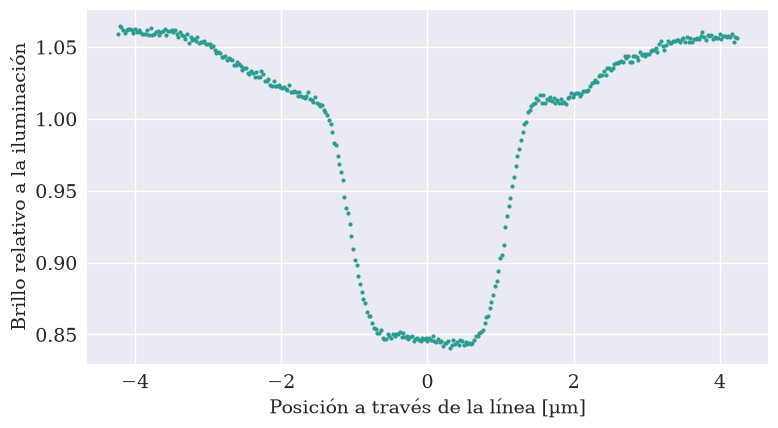

In [3]:
b = rs.borde_reticula()
fig, ax = plt.subplots(figsize=(8, 4.5))
s = np.abs(b["u"]) < 45
ax.plot(b["u"][s] * ESCALA_UM, b["perfil"][s], "o", ms=3, color=SERIE1, zorder=3, label="Perfil de una línea de la retícula")
ax.set_xlabel("Posición a través de la línea [µm]")
ax.set_ylabel("Brillo relativo a la iluminación")
guardar(fig, "borde_reticula")
print("ancho del borde (a media altura de la pendiente): %.1f px = %.0f nm, igual de los dos lados (%s px)"
      % (b["fwhm_borde_px"], b["fwhm_borde_px"] * NM, ", ".join("%.2f" % v for v in b["fwhm_por_lado"])))
print("ancho de la línea: %.1f px = %.2f µm | la línea baja el brillo %.0f %%" % (b["ancho_linea_px"], b["ancho_linea_px"] * ESCALA_UM, 100 * b["contraste"]))
anotar("nitidez de la óptica (ancho de un borde)", b["fwhm_borde_px"] * NM, "nm", "bordes de las líneas de la retícula")
csv(pd.DataFrame(dict(posicion_um=b["u"] * ESCALA_UM, brillo_relativo=b["perfil"])), "resolucion_borde_reticula.csv")

Un borde abrupto ocupa unos **0.5 µm** en la imagen (5 px). Esa es la resolución óptica: detalles más chicos que eso no se distinguen, y por eso la partícula se ve como un anillo borroso y no como un disco de borde neto. Si la retícula estaba algo fuera de foco al sacar la foto, la óptica es mejor que esto: es una cota.

**Resolver dos puntos no es lo mismo que ubicar el centro de un objeto.** Lo primero está limitado por esos 0.5 µm. Lo segundo, no: se puede ubicar el centro de una mancha de 3.5 µm con un error cien veces menor que su tamaño, igual que se puede ubicar el centro de una montaña con mucha más precisión que su ancho.

### Ruido de la cámara

El ruido de un píxel se mide comparando dos cuadros seguidos en una zona donde no cambia nada.

In [4]:
filas = []
for nombre, cuadros in ((GRAB, [1500, 1700, 1900, 3000, 3100]), ("BARRIDO STEPSIZE 3", [4700, 4750, 4800, 5600, 5700])):
    pg = pags if nombre == GRAB else tr.paginas(nombre)
    fd = fondo if nombre == GRAB else rs.fondo_mediana(pg)
    r = rs.ruido_de_pixel(pg, fd, cuadros)
    filas.append(dict(grabacion=nombre, brillo_del_fondo_cuentas=r["fondo_cuentas"], ruido_cuentas=r["cuentas"],
                      ruido_relativo_pct=100 * r["relativo"], parecido_con_el_pixel_vecino=r["correlacion_vecinos"]))
ruido = pd.DataFrame(filas)
csv(ruido, "resolucion_ruido_de_pixel.csv")
RUIDO_REL = ruido.ruido_relativo_pct.iloc[0] / 100
anotar("ruido de un píxel", 100 * RUIDO_REL, "% del brillo", "diferencia entre cuadros seguidos, BARRIDO 1")
anotar("contraste de la partícula (profundidad del anillo oscuro)", 100 * (1 - plant340.min()), "% del brillo", "imagen promedio de la partícula 340")
print("la partícula baja el brillo hasta %.0f %% en su anillo oscuro; el ruido de un píxel es %.1f %%" % (100 * (1 - plant340.min()), 100 * RUIDO_REL))
ruido.round(2)

la partícula baja el brillo hasta 15 % en su anillo oscuro; el ruido de un píxel es 1.8 %


,grabacion,brillo_del_fondo_cuentas,ruido_cuentas,ruido_relativo_pct,parecido_con_el_pixel_vecino
0,BARRIDO 1,117.78,2.10,1.79,0.49
1,BARRIDO STEPSIZE 3,66.51,1.05,1.59,0.45


- La imagen es de 8 bits (0 a 255). El fondo está en 118 cuentas en `BARRIDO 1` y en 67 en las grabaciones de más tarde, que son más oscuras.
- El ruido de un píxel es **1.6 a 1.8 % del brillo** (1 a 2 cuentas). La partícula cambia el brillo un 15 %: se ve bien, pero no sobra.
- El ruido de píxeles vecinos se parece (0.45 a 0.5 en una escala de 0 a 1). Es lo esperable de una cámara color, que arma cada píxel con sus vecinos. Importa porque promediar píxeles vecinos ayuda menos de lo que ayudaría si fueran independientes.

## 2. Cómo se mide el centro con menos de un píxel

La conversión a CSV ubica el centro por **simetría radial**: en cada punto de la imagen el brillo cambia más rápido en la dirección que apunta al centro de la partícula (o en la opuesta). Se traza esa recta en cada píxel y el centro es el punto que mejor coincide con todas. Participan todos los píxeles del borde de la partícula, y el resultado no tiene por qué caer en un número entero de píxeles.

**Prueba con corrimientos conocidos.** Para saber si eso funciona se toma la imagen promedio de una partícula real, se la corre una fracción conocida de píxel, se la pega sobre zonas reales del video sin partículas (así tiene el ruido verdadero de la cámara) y se la localiza con el mismo código de la conversión. Si la medición es buena, tiene que devolver el corrimiento que se le puso.

60 mediciones por corrimiento (12 lugares × 5 cuadros). Un píxel = 94.6 nm.
error del promedio: como mucho 0.005 px = 0.5 nm entre 0.1 y 1 px; 0.019 px a 2 y 3 px
error de UNA medición (cambia de un cuadro al siguiente): 0.164 px = 16 nm en x, 0.165 px = 16 nm en y
corrimiento fijo que mete el fondo de cada lugar: 0.070 px = 7 nm en x, 0.057 px = 5 nm en y


,corrimiento_px,medido_px,error_px,error_nm,n
0,0.1,0.1001,0.0001,0.0134,60
1,0.2,0.2004,0.0004,0.0425,60
2,0.3,0.2990,-0.0010,-0.0980,60
3,0.4,0.3996,-0.0004,-0.0398,60
4,0.5,0.4994,-0.0006,-0.0527,60
5,0.6,0.5987,-0.0013,-0.1268,60
6,0.7,0.6975,-0.0025,-0.2394,60
7,0.8,0.7963,-0.0037,-0.3539,60
8,0.9,0.8957,-0.0043,-0.4071,60
9,1.0,0.9951,-0.0049,-0.4606,60


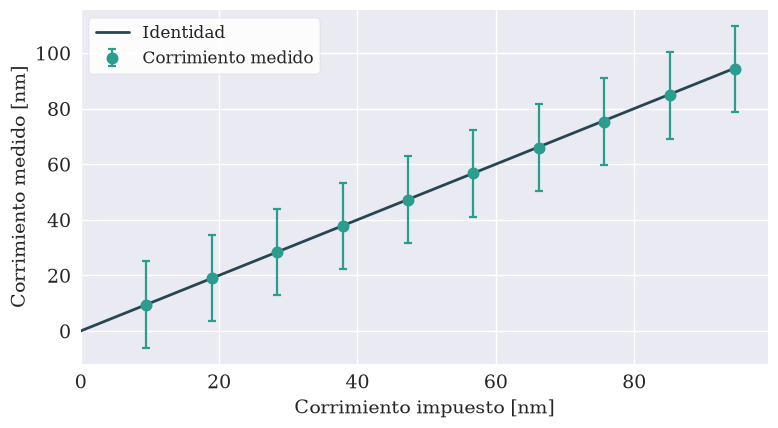

In [5]:
modelo = q[q.particula == 164].iloc[0]                       # la partícula quieta con más cuadros
plant, n_plant = rs.plantilla(pags, fondo, modelo)
pila, lugares = rs.pilas_vacias(GRAB, pags, fondo, int(modelo.cuadro_ini), int(modelo.cuadro_fin), cuantos=12, n_cuadros=40)
errores = rs.separar_errores(plant, pila)
vacios = pila[:, ::8].reshape(-1, pila.shape[2], pila.shape[3])          # 12 lugares × 5 cuadros
corrimientos = np.r_[np.arange(0.1, 1.01, 0.1), 2.0, 3.0]
corr, _ = rs.prueba_corrimientos(plant, vacios, corrimientos)
corr["error_nm"] = corr.error_px * NM
csv(corr, "resolucion_corrimientos.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
s = corr.corrimiento_px <= 1
ax.errorbar(corr.corrimiento_px[s] * NM, corr.medido_px[s] * NM, yerr=errores["temporal_x_px"] * NM, fmt="o", ms=7, capsize=3,
            elinewidth=1.6, capthick=1.6, mew=1.6, color=SERIE1, mfc=SERIE1, mec=SERIE1, zorder=3, label="Corrimiento medido")
ax.plot([0, NM], [0, NM], color=AJUSTE, lw=2, zorder=2, label="Identidad")
ax.set_xlabel("Corrimiento impuesto [nm]")
ax.set_ylabel("Corrimiento medido [nm]")
ax.set_xlim(0, None)
ax.legend(loc="upper left", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "corrimientos")
print("%d mediciones por corrimiento (12 lugares × 5 cuadros). Un píxel = %.1f nm." % (len(vacios), NM))
print("error del promedio: como mucho %.3f px = %.1f nm entre 0.1 y 1 px; %.3f px a 2 y 3 px"
      % (corr.error_px[s].abs().max(), corr.error_px[s].abs().max() * NM, corr.error_px[~s].abs().max()))
print("error de UNA medición (cambia de un cuadro al siguiente): %.3f px = %.0f nm en x, %.3f px = %.0f nm en y"
      % (errores["temporal_x_px"], errores["temporal_x_px"] * NM, errores["temporal_y_px"], errores["temporal_y_px"] * NM))
print("corrimiento fijo que mete el fondo de cada lugar: %.3f px = %.0f nm en x, %.3f px = %.0f nm en y"
      % (errores["fijo_x_px"], errores["fijo_x_px"] * NM, errores["fijo_y_px"], errores["fijo_y_px"] * NM))
anotar("error sistemático del centro (linealidad)", corr.error_px[s].abs().max() * NM, "nm", "corrimientos conocidos de 0.1 a 1 px")
anotar("error de una medición, prueba con ruido real", errores["temporal_x_px"] * NM, "nm", "partícula modelo sobre zonas vacías, entre cuadros")
anotar("corrimiento fijo según el lugar de la imagen", errores["fijo_x_px"] * NM, "nm", "partícula modelo sobre 12 zonas vacías")
corr[["corrimiento_px", "medido_px", "error_px", "error_nm", "n"]].round(4)

- **La medición es lineal.** Un corrimiento de un décimo de píxel (9.5 nm) se mide como un décimo de píxel. El error del promedio es de menos de 1 nm: no hay un «salto» de píxel en píxel.
- **Cada medición individual tiene un error de 16 nm** (0.17 px), que es la barra de la figura. Es lo que el ruido de la cámara le hace a esta forma de medir.
- **El fondo de la imagen corre el centro unos 7 nm**, distinto en cada lugar pero fijo en el tiempo. No afecta a una partícula que se queda en el mismo sitio (es un corrimiento constante); sí suma a las distancias entre lugares distintos.

## 3. La precisión real: partículas que no se mueven

La prueba anterior usa una partícula pegada a mano sobre el video. El control con datos reales son las partículas **pegadas al vidrio**: con la platina quieta su centro no cambia.

Para que la vibración o una deriva lenta de la platina no se confundan con error de medición, se usan **pares** de partículas quietas que están a la vez en el campo. La distancia real entre ellas no cambia; lo que cambia la distancia medida es el error de las dos mediciones. El error de una es el desvío de esa diferencia dividido $\sqrt 2$.

17 pares de partículas quietas en BARRIDO 1
error de una medición, por pares: mediana 33 nm (0.35 px), de 16 a 47 nm
  en x: mediana 35 nm | en y: mediana 30 nm
partícula 164 sola (la de la figura): desvío 21 nm en x, 17 nm en y
movimiento que comparten las dos partículas de un par (vibración o deriva de la platina): mediana 8 nm


,a,b,n,separacion_px,sigma_x_nm,sigma_y_nm
0,164,171,553,269.5,16.4,17.6
1,239,240,192,253.9,34.7,30.1
2,239,241,191,138.7,36.8,32.1
3,239,244,192,841.3,43.3,42.1
4,240,241,191,374.8,34.2,28.7
5,240,244,192,895.0,40.3,40.0
6,241,244,191,923.3,46.7,42.7
7,336,338,240,120.4,36.0,39.1
8,336,340,240,589.0,36.7,39.7
9,336,342,240,482.2,37.8,39.8


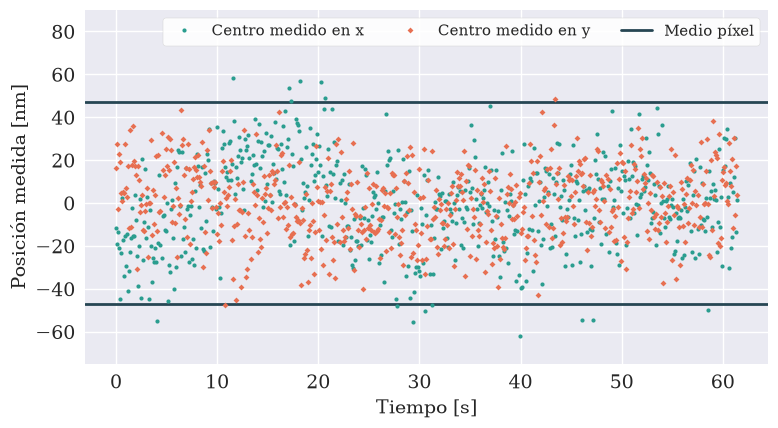

In [6]:
pares = rs.precision_pares(GRAB, q)
csv(pares, "resolucion_pares.csv")
t = rs.cargar(GRAB)["tr"]
s = t[(t.particula == modelo.particula) & (t.cuadro >= modelo.cuadro_ini) & (t.cuadro <= modelo.cuadro_fin) & t.x_px.notna() & (t.colision == 0)]
dt = np.median(np.diff(rs.cargar(GRAB)["tiempo"].t_s))
fig, ax = plt.subplots(figsize=(8, 4.5))
for col, color, fmt, nombre in (("x_px", SERIE1, "o", "Centro medido en $x$"), ("y_px", SERIE2, "D", "Centro medido en $y$")):
    v = s[col].values - np.polyval(np.polyfit(s.cuadro, s[col], 1), s.cuadro)
    ax.plot((s.cuadro.values - s.cuadro.values[0]) * dt, v * NM, fmt, ms=3, color=color, mec=color, zorder=3, label=nombre)
ax.axhline(NM / 2, color=AJUSTE, lw=2, zorder=2, label="Medio píxel")
ax.axhline(-NM / 2, color=AJUSTE, lw=2, zorder=2)
ax.set_xlabel("Tiempo [s]")
ax.set_ylabel("Posición medida [nm]")
ax.set_ylim(-75, 90)
ax.legend(loc="upper right", fontsize=11, ncol=3, facecolor="white", framealpha=0.9)
guardar(fig, "quieta_en_el_tiempo")

sig = np.r_[pares.sigma_x_px, pares.sigma_y_px] * NM
print("%d pares de partículas quietas en %s" % (len(pares), GRAB))
print("error de una medición, por pares: mediana %.0f nm (%.2f px), de %.0f a %.0f nm" % (np.median(sig), np.median(sig) / NM, sig.min(), sig.max()))
print("  en x: mediana %.0f nm | en y: mediana %.0f nm" % (pares.sigma_x_px.median() * NM, pares.sigma_y_px.median() * NM))
print("partícula %d sola (la de la figura): desvío %.0f nm en x, %.0f nm en y" % (modelo.particula, modelo.sx_px * NM, modelo.sy_px * NM))
comun = np.r_[pares.comun_x_px.abs(), pares.comun_y_px.abs()] * NM
print("movimiento que comparten las dos partículas de un par (vibración o deriva de la platina): mediana %.0f nm" % np.median(comun))
anotar("error de una medición, partículas quietas reales (mediana)", float(np.median(sig)), "nm", "17 pares de partículas pegadas al vidrio")
anotar("error de una medición, mejor par", float(sig.min()), "nm", "par de partículas quietas con mejor contraste")
anotar("error de una medición, peor par", float(sig.max()), "nm", "par de partículas quietas")
pares.assign(sigma_x_nm=pares.sigma_x_px * NM, sigma_y_nm=pares.sigma_y_px * NM)[["a", "b", "n", "separacion_px", "sigma_x_nm", "sigma_y_nm"]].round(1)

- La partícula de la figura estuvo quieta un minuto. Su centro medido se dispersa unos **20 nm**, la quinta parte de un píxel, y nunca se va más de medio píxel.
- Con los 17 pares, el error de una medición va de **16 a 47 nm** según la partícula (mediana 33 nm). Las partículas con el anillo mejor marcado se miden mejor.
- El mejor par da 16 nm, **lo mismo que la prueba con la partícula pegada a mano** de la sección 2. O sea: lo que «se mueve» una partícula pegada es error de medición, no movimiento real.
- La platina mueve a las dos partículas juntas menos de 10 nm: no es un problema.

### ¿Se podría medir mejor?

La simetría radial sirve para cualquier partícula sin saber de antemano cómo se ve. Si en cambio se compara cada cuadro con la **imagen promedio de la propia partícula** y se busca dónde encaja mejor, se aprovecha todo lo que se sabe de ella. Acá se prueba esa otra forma sobre las mismas imágenes, y se compara con lo mejor que permite el ruido (cota de Cramér–Rao, calculada para ruido independiente entre píxeles).

In [7]:
K, M = pila.shape[:2]
pos_p = np.array([[rs.localizar_por_plantilla(rs.poner(pila[i, k], plant, 0.0, 0.0), plant) for k in range(M)] for i in range(K)])
temporal_p = float(np.median(pos_p[:, :, 0].std(1)))
cota_x, cota_y = rs.cota_teorica(plant, RUIDO_REL)
# la partícula real 340, cuadro por cuadro, con las dos formas
cuadros = np.arange(int(ejemplo.cuadro_ini), int(ejemplo.cuadro_fin), 2)
real = []
for cq in cuadros:
    rec = rs.recorte(rs.cuadro_verde(pags[cq]) / fondo, ejemplo.x_px, ejemplo.y_px, rs.MEDIO)
    real.append(rs.localizar_por_plantilla(rec, plant340) + rs.localizar(rec))
real = np.array(real)
sin_recta = lambda v: v - np.polyval(np.polyfit(cuadros, v, 1), cuadros)
d_real = [float(sin_recta(real[:, k]).std()) for k in range(4)]
comp = pd.DataFrame([
    {"cómo": "simetría radial (la que se usa)", "prueba con ruido real [nm]": errores["temporal_x_px"] * NM, "partícula quieta real 340 [nm]": np.mean(d_real[2:]) * NM},
    {"cómo": "comparar con la imagen de la propia partícula", "prueba con ruido real [nm]": temporal_p * NM, "partícula quieta real 340 [nm]": np.mean(d_real[:2]) * NM},
    {"cómo": "lo mejor posible con este ruido (cota teórica)", "prueba con ruido real [nm]": cota_x * NM, "partícula quieta real 340 [nm]": np.nan}])
csv(comp, "resolucion_metodos.csv")
anotar("error de una medición comparando con la imagen de la partícula", temporal_p * NM, "nm", "prueba con ruido real; no es el método en uso")
anotar("cota teórica del error de una medición", cota_x * NM, "nm", "Cramér–Rao con ruido independiente entre píxeles")
comp.round(1)

,cómo,prueba con ruido real [nm],partícula quieta real 340 [nm]
0,simetría radial (la que se usa),15.5,23.2
1,comparar con la imagen de la propia partícula,4.6,6.6
2,lo mejor posible con este ruido (cota teórica),3.3,NaN


- Comparando con la imagen de la propia partícula el error baja **de 16 a unos 5 nm** en la prueba, y de 23 a 7 nm en una partícula real pegada al vidrio. Es casi lo mejor que permite el ruido.
- Eso dice dos cosas. Que los ~20 nm de las partículas pegadas son error del método y no movimiento real (con otro método la misma partícula «se mueve» 7 nm). Y que **hay margen para medir tres veces mejor** sin cambiar nada del experimento.
- No se cambió el método de la conversión: comparar con la imagen propia exige conocer cómo se ve cada partícula, y para la atrapada además hay que resolver el punto oscuro que deja el láser (`barrido de potencias`). Queda como mejora posible.

### Las partículas que se mueven: ¿se miden igual de bien?

Las pegadas al vidrio están siempre en foco. Las libres suben y bajan, y se ven más o menos marcadas según a qué altura estén. Para ellas no hay una posición «verdadera» con la que comparar, pero hay una forma de sacar el error de los propios datos:

> Si en un cuadro la posición salió corrida hacia la derecha por error, el paso que **llega** a ese cuadro sale más largo y el que **sale** de él, más corto. Dos pasos seguidos tienden a compensarse. El movimiento browniano no hace eso: sus pasos son independientes. De cuánto se compensan dos pasos seguidos sale el error de una medición.

En números: el promedio del producto de dos pasos seguidos vale $-\sigma^2$, con $\sigma$ el error de una medición. Se aplica a las partículas libres de los dos barridos de potencia (las mismas que dan $\gamma$ en `fuerza y pozo`). El tiempo de exposición de la cámara empuja en sentido contrario (hace que dos pasos seguidos se parezcan), así que lo que sale es un **mínimo** del error.

22 partículas libres: error de una medición de 0 a 95 nm, mediana 55 nm
   por grabación: LASER 5 mediana 62 nm (n=13) | BARRIDO POTENCIAS 2 mediana 31 nm (n=9)
   las 6 con señal sobre ruido mayor que 33: mediana 0 nm | las 16 con menos: mediana 66 nm
   ancho del paso (difusión + error): de 103 a 175 nm
   en 4 partículas dos pasos seguidos se parecen en vez de compensarse (producto de +55 a +459 nm²): es el efecto de la exposición


,grabacion,particula,pares_de_pasos,senal_sobre_ruido,ancho_del_paso_nm,producto_de_pasos_seguidos_nm2,error_de_una_medicion_nm
0,LASER 5,2,3776,22.7,150.2,-4290.5,65.5
1,LASER 5,3,2932,38.9,103.2,257.6,0.0
2,LASER 5,4,5646,32.0,167.7,-8862.5,94.1
3,LASER 5,5,5724,26.6,138.6,-3099.9,55.7
4,LASER 5,7,4248,30.7,133.1,-2592.0,50.9
5,LASER 5,10,1934,22.5,166.9,-5070.0,71.2
6,LASER 5,14,5620,26.2,149.1,-3804.4,61.7
7,LASER 5,19,2418,29.2,153.7,-4394.2,66.3
8,LASER 5,22,1632,25.9,150.8,-5360.7,73.2
9,LASER 5,24,3222,26.6,140.7,-2944.9,54.3


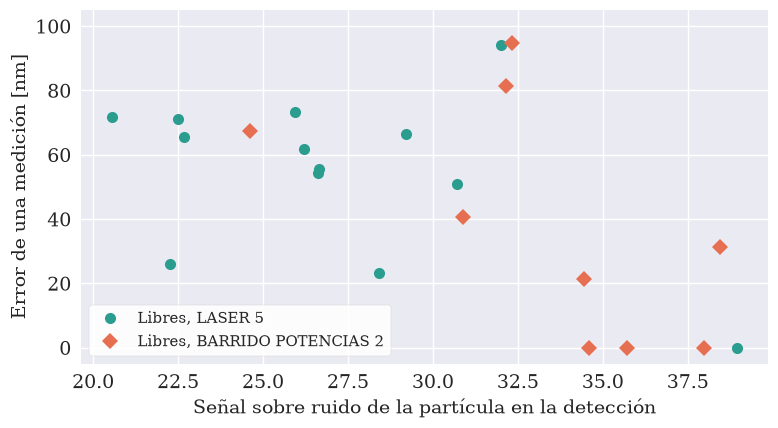

In [8]:
import trayectorias as T
lib = pd.read_csv(os.path.join(resultados("patadas"), "difusion_libres_en_trampa.csv"))
filas = []
for nombre in ("LASER 5", "BARRIDO POTENCIAS 2"):
    datos = T.cargar(os.path.join(DATOS, nombre))
    tl = datos["tr"]
    tl.loc[tl.colision == 1, ["x_px", "y_px"]] = np.nan
    tt, X, Y, ids, _ = T.matrices(datos, escala_um=ESCALA_UM, largo_min=300)
    Xs, Ys = T.sin_deriva_por_particula(tt, X, Y)
    elegidas = set(lib[(lib.grabacion == nombre) & lib.nominal_y_libre].particula)
    for k, p in enumerate(ids):
        if p not in elegidas:
            continue
        cov, var, n = [], [], 0
        for A in (Xs[:, k], Ys[:, k]):
            d = np.diff(A) * 1e3                                   # pasos [nm]
            ok = np.isfinite(d[:-1]) & np.isfinite(d[1:])
            cov.append(np.mean(d[:-1][ok] * d[1:][ok])); var.append(np.nanvar(d)); n += int(ok.sum())
        filas.append(dict(grabacion=nombre, particula=int(p), pares_de_pasos=n, senal_sobre_ruido=float(tl[tl.particula == p].z.mean()),
                          ancho_del_paso_nm=float(np.sqrt(np.mean(var))), producto_de_pasos_seguidos_nm2=float(np.mean(cov)),
                          error_de_una_medicion_nm=float(np.sqrt(max(-np.mean(cov), 0.0)))))
libres = pd.DataFrame(filas)
csv(libres, "resolucion_libres.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, color, fmt in (("LASER 5", SERIE1, "o"), ("BARRIDO POTENCIAS 2", SERIE2, "D")):
    g = libres[libres.grabacion == nombre]
    ax.plot(g.senal_sobre_ruido, g.error_de_una_medicion_nm, fmt, ms=8, color=color, mec=color, zorder=3, label="Libres, " + nombre)
ax.set_xlabel("Señal sobre ruido de la partícula en la detección")
ax.set_ylabel("Error de una medición [nm]")
ax.set_ylim(-5, 105)
ax.legend(loc="lower left", fontsize=11, facecolor="white", framealpha=0.9)
guardar(fig, "error_libres")
e = libres.error_de_una_medicion_nm
print("%d partículas libres: error de una medición de %.0f a %.0f nm, mediana %.0f nm" % (len(libres), e.min(), e.max(), e.median()))
print("   por grabación:", " | ".join("%s mediana %.0f nm (n=%d)" % (n_, g.error_de_una_medicion_nm.median(), len(g)) for n_, g in libres.groupby("grabacion", sort=False)))
print("   las %d con señal sobre ruido mayor que 33: mediana %.0f nm | las %d con menos: mediana %.0f nm"
      % ((libres.senal_sobre_ruido > 33).sum(), e[libres.senal_sobre_ruido > 33].median(), (libres.senal_sobre_ruido <= 33).sum(), e[libres.senal_sobre_ruido <= 33].median()))
print("   ancho del paso (difusión + error): de %.0f a %.0f nm" % (libres.ancho_del_paso_nm.min(), libres.ancho_del_paso_nm.max()))
positivas = libres[libres.producto_de_pasos_seguidos_nm2 > 0]
print("   en %d partículas dos pasos seguidos se parecen en vez de compensarse (producto de +%.0f a +%.0f nm²): es el efecto de la exposición"
      % (len(positivas), positivas.producto_de_pasos_seguidos_nm2.min(), positivas.producto_de_pasos_seguidos_nm2.max()))
anotar("error de una medición, partículas libres (mediana)", float(e.median()), "nm", "compensación entre pasos seguidos, %d partículas libres; es un mínimo" % len(libres))
anotar("error de una medición, partícula libre peor enfocada", float(e.max()), "nm", "compensación entre pasos seguidos")
libres.round(1)

- **Las libres se miden peor que las pegadas, y depende de cada una.** El error va de menos de 20 nm a 95 nm (mediana 55 nm), contra 16 a 47 nm de las pegadas.
- **Depende de qué tan marcada se ve la partícula**, o sea de a qué altura está respecto del foco. Las seis mejor enfocadas (señal sobre ruido mayor que 33) dan un error que no se distingue de cero; las otras dieciséis, 66 nm de mediana. La relación no es limpia: hay partículas con la misma señal y errores de 25 y de 70 nm.
- En cuatro partículas dos pasos seguidos se parecen en vez de compensarse. Es lo que hace el tiempo de exposición, y marca que **estos números son un mínimo**: en esas cuatro el error no es cero, es menor que lo que tapa la exposición (unos 20 nm). De paso, es una pista sobre la exposición de la cámara, que no se conoce (ver `../2 - potencial con patadas/DUDAS.md`).
- **Qué cambia en los otros análisis.** El coeficiente de difusión (y con él $\gamma$) sale de cómo crece el MSD con el tiempo, y un error de medición constante no cambia esa pendiente: no se ve afectado. Lo que **no** se puede hacer es sacar $D$ del ancho de un histograma de pasos: ese ancho (103 a 175 nm) mezcla la difusión con este error.


## 4. ¿Qué tan redondas son?

Se toma la imagen promedio de cada partícula quieta (150 cuadros: el ruido casi desaparece) y se mide el **radio del borde en 36 direcciones**. Si la partícula se ve redonda, el radio es el mismo en todas. Lo que se aparta se descompone en:

- una **elipse** (el radio es mayor en una dirección y menor en la perpendicular): se informa cuánto más largo es el eje mayor que el menor, en %;
- formas de **tres y cuatro lóbulos** (triángulo y cuadrado redondeados).

Dos controles: la misma medición con las dos mitades de los cuadros por separado (si da lo mismo, no es ruido), y con una partícula hecha perfectamente redonda pegada sobre fondos reales (lo que da ahí es el piso de lo que se puede distinguir).

In [9]:
filas, imagenes = [], {}
for _, f in q.iterrows():
    cu = np.unique(np.linspace(f.cuadro_ini, f.cuadro_fin, 150).round().astype(int))
    rec = [rs.recorte(rs.cuadro_verde(pags[cq]) / fondo, f.x_px, f.y_px, 40) for cq in cu]
    rec = [r for r in rec if r is not None]
    if len(rec) < 60:
        continue
    todo, m1, m2 = rs.contorno(np.mean(rec, axis=0)), rs.contorno(np.mean(rec[0::2], axis=0)), rs.contorno(np.mean(rec[1::2], axis=0))
    if "a2" not in todo or "a2" not in m1 or "a2" not in m2:
        continue
    imagenes[int(f.particula)] = (np.mean(rec, axis=0), todo)
    filas.append(dict(particula=int(f.particula), radio_um=todo["r0"] * ESCALA_UM, elipse_pct=200 * todo["a2"] / todo["r0"],
                      direccion_eje_mayor_grados=np.degrees(todo["fase2"]) % 180,
                      elipse_mitad_1_pct=200 * m1["a2"] / m1["r0"], elipse_mitad_2_pct=200 * m2["a2"] / m2["r0"],
                      direccion_mitad_1_grados=np.degrees(m1["fase2"]) % 180, direccion_mitad_2_grados=np.degrees(m2["fase2"]) % 180,
                      tres_lobulos_pct=200 * todo["a3"] / todo["r0"], cuatro_lobulos_pct=200 * todo["a4"] / todo["r0"],
                      a2_px=todo["a2"], fase2_rad=todo["fase2"], r0_px=todo["r0"]))
cont = pd.DataFrame(filas)

# piso: una partícula perfectamente redonda sobre fondos reales promediados en el tiempo
redonda = rs.plantilla_redonda(plant340)
piso = []
for i in range(pila.shape[0]):
    img = rs.poner(pila[i].mean(0), redonda, 0.0, 0.0)
    cr = rs.contorno(img[rs.MEDIO - 40:rs.MEDIO + 41, rs.MEDIO - 40:rs.MEDIO + 41])
    if "a2" in cr:
        piso.append(200 * cr["a2"] / cr["r0"])
piso = np.array(piso)
# parte común a todas: si la óptica deformara (o el píxel no fuera cuadrado), todas serían elípticas para el mismo lado
vec = np.mean(cont.a2_px / cont.r0_px * np.exp(2j * cont.fase2_rad))
comun_pct, err_comun = 200 * abs(vec), 200 * (cont.a2_px / cont.r0_px).std() / np.sqrt(len(cont))
csv(cont.drop(columns=["a2_px", "fase2_rad", "r0_px"]), "resolucion_contornos.csv")

print("%d partículas quietas medidas" % len(cont))
print("elipse (eje mayor respecto del menor): mediana %.1f %%, de %.1f a %.1f %%" % (cont.elipse_pct.median(), cont.elipse_pct.min(), cont.elipse_pct.max()))
print("las dos mitades de los cuadros difieren en %.1f %% (mediana) y la dirección en %.0f°: no es ruido"
      % ((cont.elipse_mitad_1_pct - cont.elipse_mitad_2_pct).abs().median(),
         np.median(np.abs((cont.direccion_mitad_1_grados - cont.direccion_mitad_2_grados + 90) % 180 - 90))))
print("piso (partícula redonda sobre %d fondos reales): mediana %.1f %%, máximo %.1f %%" % (len(piso), np.median(piso), piso.max()))
print("parte común a todas (deformación de la óptica o píxel no cuadrado): %.1f ± %.1f %%" % (comun_pct, err_comun))
print("tres lóbulos: mediana %.1f %% | cuatro lóbulos: mediana %.1f %%" % (cont.tres_lobulos_pct.median(), cont.cuatro_lobulos_pct.median()))
print("radio del borde: de %.2f a %.2f µm; %d de más de 1.5 µm y %d de menos" % (cont.radio_um.min(), cont.radio_um.max(), (cont.radio_um > 1.5).sum(), (cont.radio_um <= 1.5).sum()))
anotar("elipse aparente del contorno (mediana)", cont.elipse_pct.median(), "%", "%d partículas pegadas al vidrio" % len(cont))
anotar("piso de la medición de elipse", float(np.median(piso)), "%", "partícula redonda sobre fondos reales")
anotar("deformación común a todas las partículas", comun_pct, "%", "promedio con dirección de las elipses; error ± %.1f" % err_comun)
cont[["particula", "radio_um", "elipse_pct", "direccion_eje_mayor_grados", "elipse_mitad_1_pct", "elipse_mitad_2_pct", "tres_lobulos_pct", "cuatro_lobulos_pct"]].round(2)

13 partículas quietas medidas
elipse (eje mayor respecto del menor): mediana 5.2 %, de 0.3 a 12.3 %
las dos mitades de los cuadros difieren en 0.2 % (mediana) y la dirección en 1°: no es ruido
piso (partícula redonda sobre 12 fondos reales): mediana 0.4 %, máximo 1.2 %
parte común a todas (deformación de la óptica o píxel no cuadrado): 1.3 ± 0.9 %
tres lóbulos: mediana 3.1 % | cuatro lóbulos: mediana 2.8 %
radio del borde: de 1.06 a 1.84 µm; 6 de más de 1.5 µm y 7 de menos


,particula,radio_um,elipse_pct,direccion_eje_mayor_grados,elipse_mitad_1_pct,elipse_mitad_2_pct,tres_lobulos_pct,cuatro_lobulos_pct
0,6,1.71,3.33,40.48,3.71,2.94,5.02,3.01
1,53,1.73,0.33,59.31,0.36,0.29,3.13,1.21
2,164,1.77,5.19,124.26,5.19,5.24,1.76,2.21
3,171,1.15,8.22,58.74,8.27,8.14,3.70,2.78
4,239,1.31,7.47,174.69,7.93,7.05,4.35,3.53
5,240,1.06,6.22,82.50,6.55,5.85,3.06,3.98
6,241,1.29,12.26,56.18,12.09,12.45,8.41,8.93
7,244,1.81,4.16,52.23,5.94,3.51,9.11,4.55
8,336,1.73,1.07,63.52,1.13,1.03,1.34,0.56
9,338,1.37,8.63,174.40,8.59,8.64,2.11,1.86


las ocho imágenes, de mayor a menor radio: partículas [340, 244, 164, 53, 336, 6, 338, 239] | cada imagen mide 7.7 µm de lado


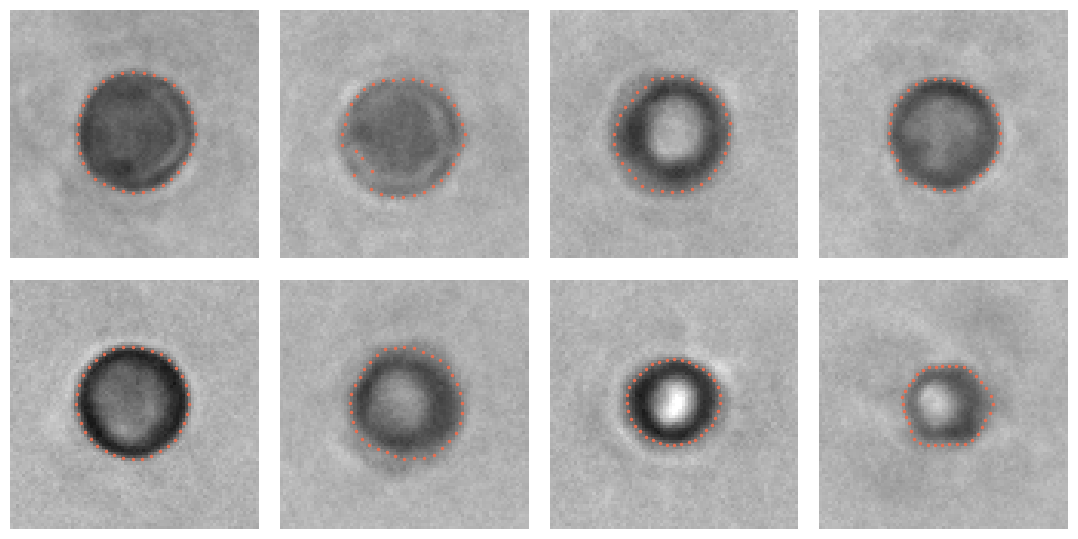

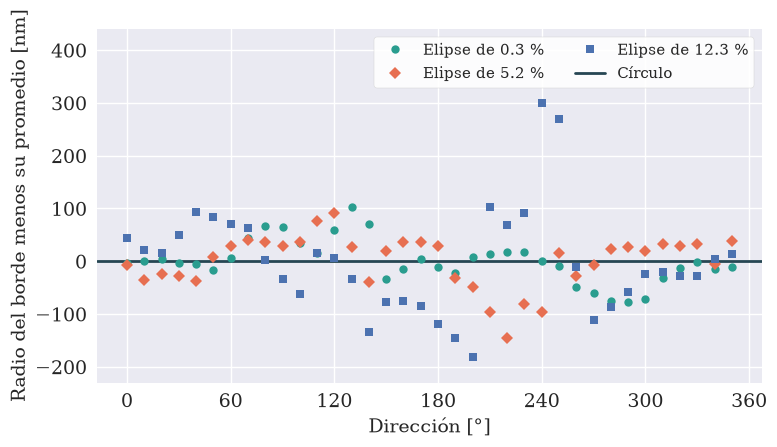

In [10]:
orden = cont.sort_values("radio_um", ascending=False).particula.tolist()[:8]
fig, axs = plt.subplots(2, 4, figsize=(11, 5.8))
for ax, pid in zip(axs.ravel(), orden):
    img, cr = imagenes[pid]
    lado = img.shape[0] * ESCALA_UM
    ax.imshow(img, cmap="gray", vmin=0.8, vmax=1.08, extent=(0, lado, lado, 0))
    ax.plot((cr["centro"][0] + 0.5 + cr["r_px"] * np.cos(cr["angulo"])) * ESCALA_UM, (cr["centro"][1] + 0.5 + cr["r_px"] * np.sin(cr["angulo"])) * ESCALA_UM,
            "o", ms=2.5, color=SERIE2)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
guardar(fig, "contornos_imagenes")

fig, ax = plt.subplots(figsize=(8, 4.5))
for pid, color, fmt in zip(cont.sort_values("elipse_pct").particula.iloc[[0, len(cont) // 2, -1]], (SERIE1, SERIE2, AZUL), "oDs"):
    img, cr = imagenes[int(pid)]
    ax.plot(np.degrees(cr["angulo"]), (cr["r_px"] - cr["r0"]) * NM, fmt, ms=6, color=color, mec=color, zorder=3,
            label="Elipse de %.1f %%" % cont.set_index("particula").elipse_pct[pid])
ax.axhline(0, color=AJUSTE, lw=2, zorder=2, label="Círculo")
ax.set_xlabel("Dirección [°]"); ax.set_ylabel("Radio del borde menos su promedio [nm]")
ax.set_xticks(np.arange(0, 361, 60))
ax.set_ylim(-230, 440)
ax.legend(loc="upper right", fontsize=11, ncol=2, facecolor="white", framealpha=0.9)
guardar(fig, "contorno_radio_direccion")
print("las ocho imágenes, de mayor a menor radio: partículas", orden, "| cada imagen mide %.1f µm de lado" % (81 * ESCALA_UM))

- **Se ven redondas dentro de un 5 %.** El contorno se aparta de un círculo entre 0.3 y 12 % según la partícula (mediana 5 %): el eje mayor es un 5 % más largo que el menor, unos 90 nm de diferencia sobre 1.8 µm de radio.
- **No es ruido**: las dos mitades de los cuadros dan la misma elipse, con la misma dirección.
- **No es la óptica**: cada partícula está alargada para un lado distinto. La parte común a todas es de 1.3 ± 0.9 %, compatible con cero. De paso, eso dice que **la escala es la misma en $x$ y en $y$ dentro de un 1 a 2 %** (la retícula solo la mide en $x$).
- **No es el fondo ni el método**: una partícula perfectamente redonda pegada sobre el fondo real da 0.4 % (1.2 % como mucho). Ese es el piso de lo que se puede distinguir.
- Además de la elipse hay deformaciones de tres y cuatro lóbulos de unos 3 % (medianas).
- **Hay dos tamaños**: radio del borde de 1.7 a 1.85 µm, y de 1.1 a 1.4 µm.

Lo que **no** se puede decir es si ese 5 % es de la partícula. Se mide el borde de una imagen borrosa (la óptica no distingue menos de 0.5 µm), no el borde del material. Una partícula perfectamente esférica apoyada con una mota de suciedad al lado, o iluminada un poco de costado, daría lo mismo. Y son partículas **pegadas**, que pueden no ser representativas: a las libres no se les puede medir así porque giran y se mueven.

In [11]:
res = pd.DataFrame(resumen)
csv(res, "resolucion_resumen.csv")
res.round(2)

,magnitud,valor,unidad,como
0,tamaño del píxel,94.61,nm,retícula de 0.01 mm (escala y catálogo)
1,diámetro aparente de una partícula,38.97,px,contorno de la partícula quieta 340
2,nitidez de la óptica (ancho de un borde),496.70,nm,bordes de las líneas de la retícula
3,ruido de un píxel,1.79,% del brillo,"diferencia entre cuadros seguidos, BARRIDO 1"
4,contraste de la partícula (profundidad del ani...,14.71,% del brillo,imagen promedio de la partícula 340
5,error sistemático del centro (linealidad),0.46,nm,corrimientos conocidos de 0.1 a 1 px
6,"error de una medición, prueba con ruido real",15.52,nm,"partícula modelo sobre zonas vacías, entre cua..."
7,corrimiento fijo según el lugar de la imagen,6.64,nm,partícula modelo sobre 12 zonas vacías
8,"error de una medición, partículas quietas real...",33.16,nm,17 pares de partículas pegadas al vidrio
9,"error de una medición, mejor par",16.42,nm,par de partículas quietas con mejor contraste


## Conclusión

**Cómo se resuelven distancias más chicas que un píxel.** No se resuelven en el sentido óptico: la imagen no distingue detalles de menos de 0.5 µm. Lo que se mide es **dónde está el centro** de una partícula que ocupa más de mil píxeles, y eso se puede ubicar con mucha más precisión que un píxel porque todos los píxeles del borde aportan. La prueba directa: corriendo la imagen de una partícula 9.5 nm (un décimo de píxel), la medición devuelve 9.5 nm.

| | Valor |
|---|---|
| Tamaño del píxel | 94.6 nm |
| Imagen | 1280 × 1024 px, 121 × 97 µm, 8 bits |
| Nitidez de la óptica (ancho de un borde abrupto) | 0.5 µm (5 px) |
| Partícula nominal en la imagen | 39 px de diámetro, unos 1200 px |
| Ruido de un píxel | 1.6 a 1.8 % del brillo |
| Contraste de la partícula | 15 % del brillo |

**Precisión del centro, por cuadro**

| | Error de una medición |
|---|---|
| Error sistemático (linealidad, corrimientos de 0.1 a 1 px) | menos de 1 nm |
| Corrimiento fijo según el lugar de la imagen | 5 a 7 nm |
| Partícula pegada al vidrio, la mejor | 16 nm (0.17 px) |
| Partículas pegadas al vidrio, mediana de 17 pares | 33 nm (0.35 px), de 16 a 47 |
| Partículas libres | de menos de 20 a 95 nm, mediana 55 nm |
| Partícula atrapada (`barrido de potencias`) | 19 a 22 nm en `LASER 5`, 32 a 39 nm en `BARRIDO POTENCIAS 2` |
| Lo mejor posible con este ruido de cámara | 3 nm |
| Comparando con la imagen de la propia partícula (no es lo que se usa) | 5 a 7 nm |

- El error es **al azar de un cuadro al otro**: promediando $N$ cuadros baja como $1/\sqrt N$. Por eso se puede medir el centro del pozo con pocos nm aunque cada cuadro tenga 20 o 30.
- **Contra qué hay que compararlo.** A 30 mW la partícula atrapada se mueve unos 45 nm por agitación térmica: el error de medición (20 a 35 nm) es comparable, y por eso en `barrido de potencias` se lo resta de la varianza antes de calcular la rigidez. En las patadas (`fuerza y pozo`) los desplazamientos son de micrones: ahí no pesa.
- **Las partículas libres se miden peor** porque se salen de foco. Eso no cambia $D$ ni $\gamma$ (salen de la pendiente del MSD), pero sí invalida sacar $D$ del ancho de un histograma de pasos.

**Forma de las partículas.** Las 13 pegadas al vidrio se ven redondas dentro de un 5 % (mediana; de 0.3 a 12 %). Esa deformación es real en la imagen (se repite entre mitades de los cuadros, y el piso del método es 0.4 %) y no viene de la óptica (cada una apunta para un lado distinto; la parte común es 1.3 ± 0.9 %). Hay dos tamaños: radio aparente de 1.7 a 1.85 µm y de 1.1 a 1.4 µm.

**Lo que este análisis no alcanza a decir**

- **Si el 5 % es de la partícula o de cómo se ve.** Se mide el borde de una imagen borrosa, no del material. Suciedad pegada al lado o una iluminación algo inclinada darían lo mismo.
- **La forma de las partículas libres y de la atrapada**: giran y se mueven, y no se puede promediar su imagen. Las pegadas pueden no ser representativas (quizás se pegaron justamente las deformes o sucias).
- **La resolución óptica exacta**: los 0.5 µm son una cota. Si la retícula estaba algo fuera de foco, la óptica es mejor.
- **El error de las libres es un mínimo**: la exposición de la cámara, que no se conoce, tapa parte.
- **La precisión en las grabaciones más oscuras** (`BARRIDO STEPSIZE 3` y siguientes) solo se probó con una partícula: da parecido (15 a 22 nm en la prueba, 29 a 33 nm la real; números de la exploración, no de este notebook).

**Una mejora posible, sin tocar el experimento.** Localizar comparando con la imagen promedio de la propia partícula baja el error de 16–23 nm a 5–7 nm en las pegadas. Para la atrapada serviría para medir mejor la rigidez a potencia alta, donde el movimiento térmico es más chico. No se hizo: hay que resolver antes el punto oscuro que deja el láser sobre la partícula.

CSV de esta sección: `resultados/resolucion_*.csv` (el resumen está en `resolucion_resumen.csv`).
